In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import warnings
warnings.filterwarnings("ignore")

# Выбор товара

In [2]:
df = pd.read_excel('/content/Online_Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.dtypes

,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


In [4]:
df['StockCode'].value_counts()[df['StockCode'].value_counts() > 1000].index

Index(['85123A',    22423, '85099B',    47566,    20725,    84879,    22720,
          22197,    21212,    20727,    22383,    22457,    23203,   'POST',
          22386,    22469,    22960,    21931,    22086,    22411,    20728,
          22382,    22961,    22666,    23298,    22699,    22384,    23209,
          82482,    22993,    22727,    22697,    23206,    22178,    20724,
          23084,    20726,    22726,    21080,    23199],
      dtype='object', name='StockCode')

In [5]:
df['StockCode'].value_counts()[df['StockCode'].value_counts() > 1000].values

array([2313, 2203, 2159, 1727, 1639, 1502, 1477, 1476, 1385, 1350, 1348,
       1280, 1267, 1256, 1251, 1239, 1229, 1214, 1210, 1202, 1197, 1192,
       1182, 1180, 1179, 1138, 1137, 1135, 1129, 1111, 1107, 1085, 1084,
       1072, 1068, 1067, 1061, 1026, 1015, 1009])

In [6]:
df[df['StockCode'] == 23199]
# Решил выбрать наименьший товар из тех, о которых есть более 1000 записей
# Это JUMBO BAG APPLES - авоська с принтом яблок

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
153157,549732,23199,JUMBO BAG APPLES,10,2011-04-11 16:47:00,2.08,15615.0,United Kingdom
153312,549737,23199,JUMBO BAG APPLES,20,2011-04-12 09:03:00,2.08,13599.0,United Kingdom
153503,549749,23199,JUMBO BAG APPLES,10,2011-04-12 10:45:00,2.08,12928.0,United Kingdom
154593,549928,23199,JUMBO BAG APPLES,100,2011-04-13 10:20:00,1.79,16684.0,United Kingdom
155140,549969,23199,JUMBO BAG APPLES,100,2011-04-13 14:24:00,1.65,13408.0,United Kingdom
...,...,...,...,...,...,...,...,...
539787,581439,23199,JUMBO BAG APPLES,1,2011-12-08 16:30:00,4.13,NaN,United Kingdom
541116,581492,23199,JUMBO BAG APPLES,2,2011-12-09 10:03:00,4.13,NaN,United Kingdom
541482,581498,23199,JUMBO BAG APPLES,6,2011-12-09 10:26:00,4.13,NaN,United Kingdom
541757,581574,23199,JUMBO BAG APPLES,10,2011-12-09 12:09:00,2.08,12526.0,Germany


In [7]:
df[df['StockCode'] == 23199]['Description'].value_counts()
# Фильтровать по str.contains как в семинаре не будем - товар итак унифицирован по коду

,count
Description,
JUMBO BAG APPLES,1009


In [8]:
df[(df['StockCode'] == 23199)  & ~df['InvoiceNo'].astype('str').str.startswith('C')]['Description'].value_counts()

,count
Description,
JUMBO BAG APPLES,988


# Функции

In [9]:
# Шаг 1
def load_time_series(freq, file_path='/content/Online_Retail.xlsx', stock_code=23199):
    # Загрузка и фильтрация данных
    df = pd.read_excel(file_path)
    mask = (df['StockCode'].astype(str) == str(stock_code)) & \
           (~df['InvoiceNo'].astype(str).str.startswith('C'))
    filtered_df = df[mask].copy()

    # Преобразование во временной ряд
    sales_series = (
        filtered_df
        .set_index('InvoiceDate')[['Quantity']]
        .resample(freq)
        .sum()['Quantity']
    )
    return sales_series

In [10]:
# Шаг 2
def visualize_sales(series, show_zeros=True):
    # Визуализируем ряд. Либо выделяем пропуски (то бишь нули) красным, либо нет
    plt.figure(figsize=(20, 5))
    plt.plot(series.index, series)
    if show_zeros:
        plt.scatter(series[series == 0].index, series[series == 0], color='red')
    plt.xticks(series.index[::5], rotation=90)
    plt.show()

def clear_sales(series, upper_limit):
    # Обработка выбросов клипом сверху
    return series.clip(0, upper_limit)

In [11]:
# Шаг 3
def analyze_sales(series):
    # Расчитываем основные статистики
    mu = series.mean()
    std = series.std()
    cv = std / mu if mu != 0 else 0
    skew = series.skew()
    kurt = series.kurtosis()
    print(f"Среднее (mu): {mu:.2f}")
    print(f"Стандартное отклонение (std): {std:.2f}")
    print(f"Коэффициент вариации (cv): {cv:.2f}")
    print(f"Асимметрия (skew): {skew:.2f}")
    print(f"Эксцесс (kurt): {kurt:.2f}")

    # Визуализируем изменение уровня и разброса значений во времени
    exp_mean = series.expanding().mean()
    exp_std = series.expanding().std()
    plt.figure(figsize=(15, 4))
    plt.plot(exp_mean.index, exp_mean, label='Мат ожидание от времени', color='blue')
    plt.plot(exp_std.index, exp_std, label='Дисперсия от времени', color='orange')
    plt.title("Изменение уровня и разброса значений во времени")
    plt.legend()
    plt.grid()
    plt.show()

Для шага 4 крайне удобно использовать встроенные функции - переписывать их под вызов своих я не стал

In [12]:
# Шаг 5
def check_stationarity(series, alpha=0.05):
    clean_series = series.dropna()

    # Тест ADF. Нулевая гипотеза H0: ряд нестационарен, есть единичный корень
    adf_result = adfuller(clean_series, autolag='AIC')
    adf_stat, adf_pvalue = adf_result[0], adf_result[1]
    adf_reject_h0 = adf_pvalue < alpha

    # Тест KPSS. Нулевая гипотеза H0: ряд стационарен
    kpss_result = kpss(clean_series, regression='c', nlags='auto')
    kpss_stat, kpss_pvalue = kpss_result[0], kpss_result[1]
    kpss_reject_h0 = kpss_pvalue < alpha

    # Вывод статистик
    print(f"ADF Statistic: {adf_stat:.4f} | p-value: {adf_pvalue:.4f} -> {'Отвергает H0' if adf_reject_h0 else 'Не отвергает H0'}")
    print(f"KPSS Statistic: {kpss_stat:.4f} | p-value: {kpss_pvalue:.4f} -> {'Отвергает H0' if kpss_reject_h0 else 'Не отвергает H0'}")

    # Интерпретация по таблице с лекции
    if adf_reject_h0 and not kpss_reject_h0:
        interpretation = "Есть согласованные свидетельства в пользу стационарности"
    elif not adf_reject_h0 and kpss_reject_h0:
        interpretation = "Есть согласованные свидетельства в пользу нестационарности"
    elif not adf_reject_h0 and not kpss_reject_h0:
        interpretation = "Результат неоднозначен"
    else: # adf_reject_h0 and kpss_reject_h0
        interpretation = "Результаты противоречат простой картине; возможны структурные сдвиги, \
        неверная спецификация тренда или другие особенности ряда"
    print(f"Интерпретация: {interpretation}")

# Прогнозирование продаж: анализ и предобработка временного ряда

In [13]:
sales = load_time_series(freq='D')

In [14]:
sales.describe()

,Quantity
count,243.000000
mean,61.399177
std,103.023914
min,0.000000
25%,9.000000
50%,30.000000
75%,67.000000
max,1054.000000


In [15]:
sales.isna().sum()

np.int64(0)

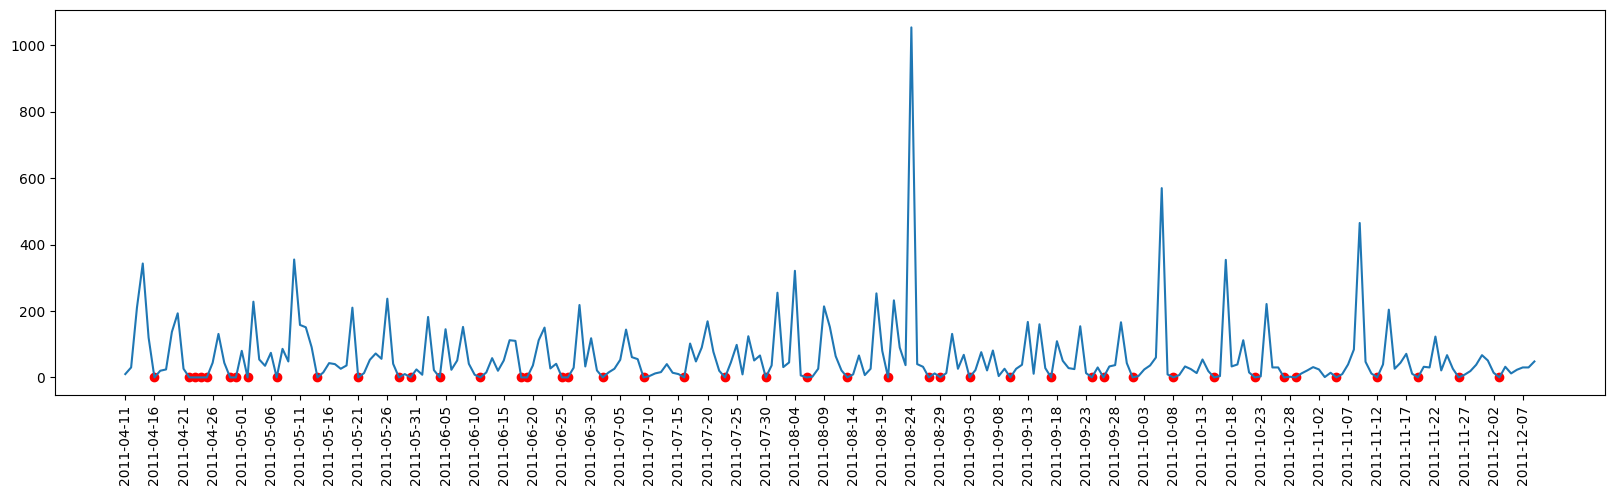

In [16]:
visualize_sales(sales)

In [17]:
sales.nlargest(5)

,Quantity
InvoiceDate,
2011-08-24,1054
2011-10-06,570
2011-11-09,465
2011-05-10,355
2011-10-17,354


In [18]:
# Выбросы удалять не стоит - это реальные данные
# Вместо этого заменим пиковые значения 99 перцентилем
sales.quantile(0.99)

np.float64(418.79999999999825)

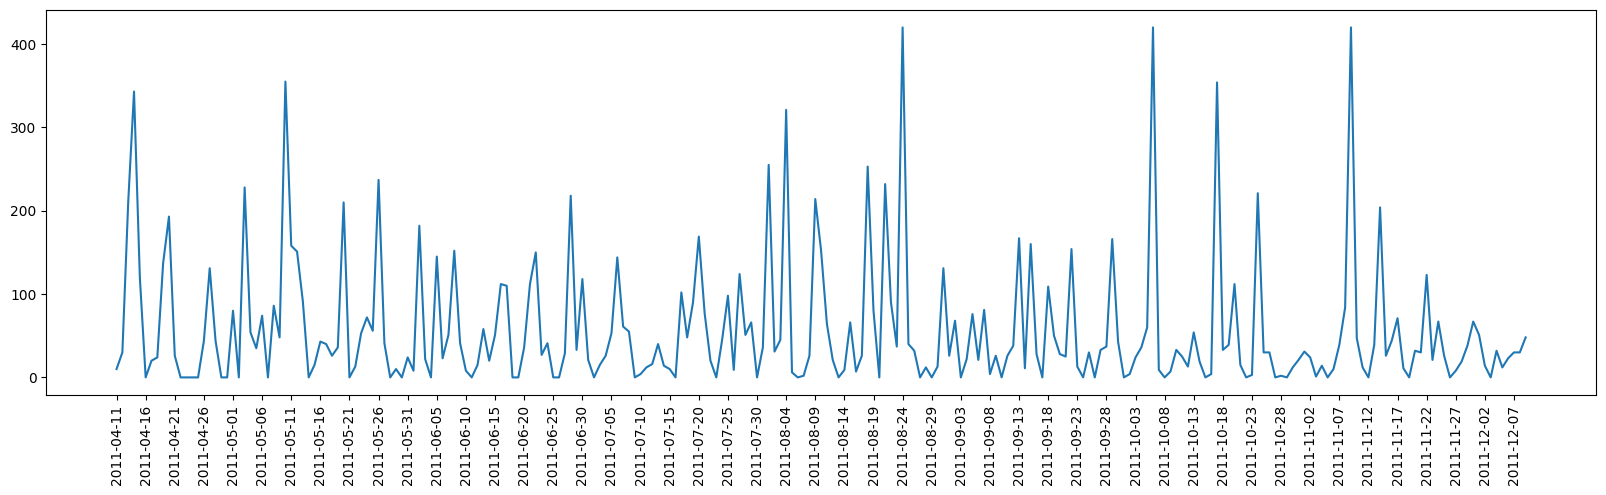

In [19]:
sales = clear_sales(sales, 420)
visualize_sales(sales, show_zeros=False)

In [20]:
sales.describe()

,Quantity
count,243.000000
mean,57.987654
std,79.894066
min,0.000000
25%,9.000000
50%,30.000000
75%,67.000000
max,420.000000


Среднее (mu): 57.99
Стандартное отклонение (std): 79.89
Коэффициент вариации (cv): 1.38
Асимметрия (skew): 2.39
Эксцесс (kurt): 6.35


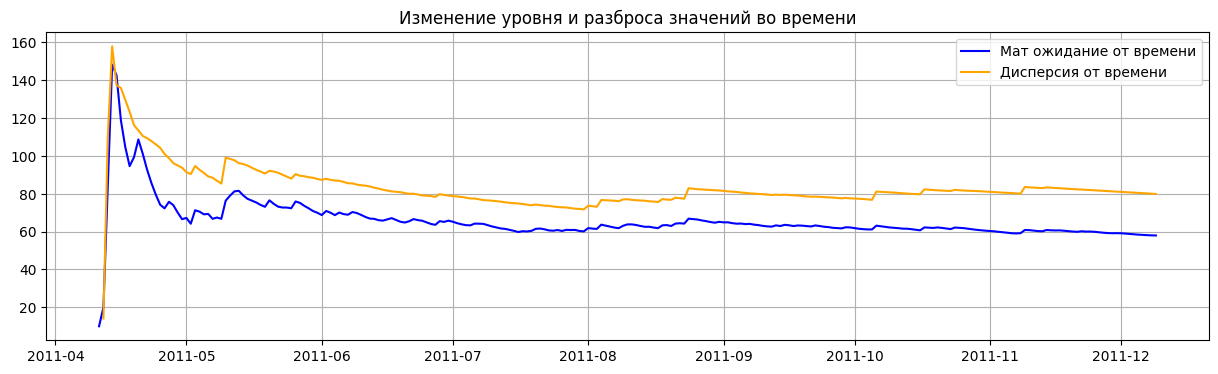

In [21]:
analyze_sales(sales)

Мат ожидание и дисперсия постоянны во времени, это *признаки стационарного ряда*

Для декомпозиции временного ряда буду использовать **аддитивные модели**, так как мультипликативная модель при нулевых значениях в данных будет плохо себя показывать

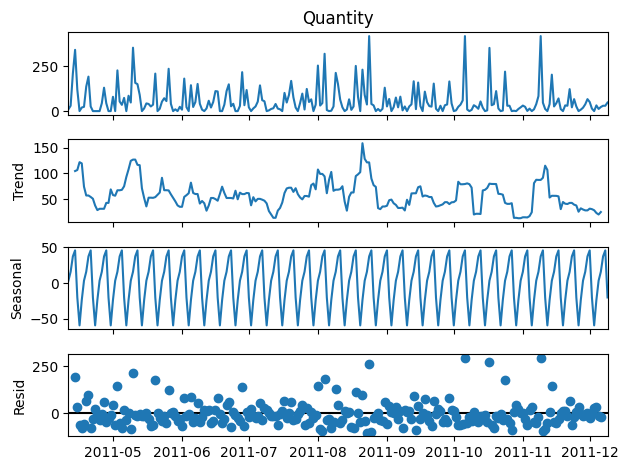

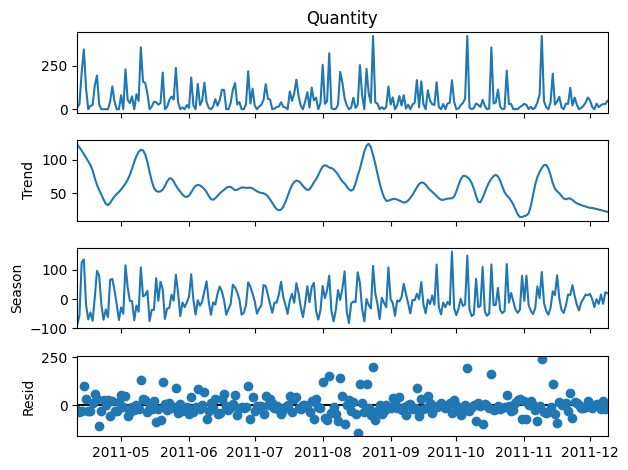

In [22]:
seasonal_decompose(sales, model='additive', period=7).plot()
STL(sales, seasonal=7).fit().plot()
plt.show()

Обе модели не выделяют явный тренд, показывая волнообразные колебания - спрос на авоськи меняется в течение года

seasonal_decompose показывает стабильный паттерн сезонности в силу своей реализации. Более адекватный результат демонстрирует STL-декомпозиция, которая позволяет сезонности медленно меняться со временем: на ней видны просадки продаж авосек в середине и конце года (пики продаж меньше)

В остатках видны выбросы, достигающие 250 - аддитивные модели не улавливают всплески оптовых закупок, что нормально

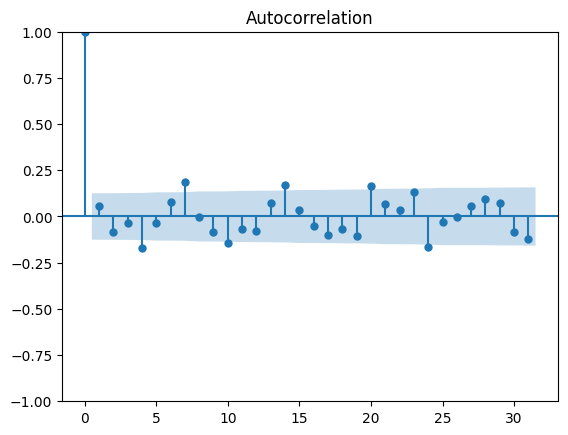

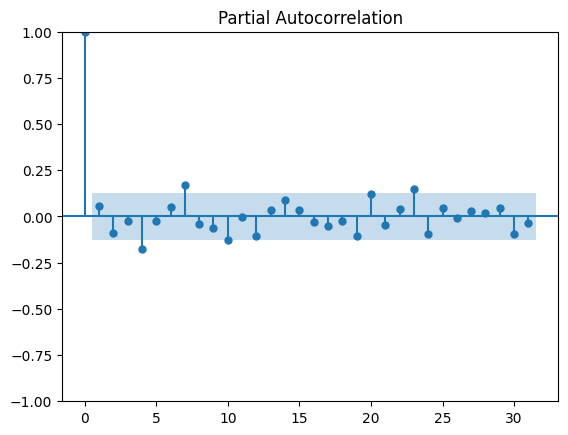

In [23]:
plot_acf(sales, lags=31)
plot_pacf(sales, lags=31)
plt.show()

По ACF и PACF видна слабая автокорреляция от 4 и 7 лагов - определенная сезонность есть, в будущем эти параметры можно будет использовать для построения моделей

In [24]:
check_stationarity(sales)

ADF Statistic: -5.2788 | p-value: 0.0000 -> Отвергает H0
KPSS Statistic: 0.2654 | p-value: 0.1000 -> Не отвергает H0
Интерпретация: Есть согласованные свидетельства в пользу стационарности


Результаты расширенного теста Дики Фуллера и теста KPSS согласуются - исходный ряд стационарен, преобразований не требуется